## Practical 07: Spam SMS Detection

### Aim
Clean SMS text, extract TF-IDF features and classify spam versus legitimate messages.

### Model
TF-IDF + Naive Bayes

### Data
80 original, manually authored teaching messages: 40 spam and 40 ham. No downloaded SMS corpus or personal messages are used.

### Theory
Text is lowercased, URLs and numbers are normalized, and punctuation is removed. TF-IDF downweights frequent terms; Multinomial Naive Bayes uses class-conditional token counts with additive smoothing.

### Method
Load or generate data, inspect features and labels, fit preprocessing on training data, train the required model, evaluate and visualize the output. See the implementation for the task-specific split.

### Limitation
The small authored corpus illustrates the pipeline only. Its test metrics are not a real-world spam benchmark.

In [ ]:
# Colab CPU runtime is sufficient. No external dataset download is needed.
%pip -q install 'scikit-learn>=1.5,<2' 'pandas>=2.2,<4' 'matplotlib>=3.8,<4'


In [1]:
"""Shared imports and evaluation; also embedded in every standalone notebook."""
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
    IsolationForest, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import (TfidfVectorizer,
    CountVectorizer, ENGLISH_STOP_WORDS)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris, load_breast_cancer, load_digits
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error,
    r2_score, silhouette_score, average_precision_score)
SEED = 42
rng = np.random.default_rng(SEED)
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (7, 4), 'font.size': 10})

def plot_save(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

def tabular_preprocessor(frame):
    numeric = frame.select_dtypes(include='number').columns.tolist()
    category = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median'),
                                  StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
          OneHotEncoder(handle_unknown='ignore', sparse_output=False)), category)])

def evaluate(model, X, y, name, classification=True, chronological=False):
    # All fitted preprocessing stays inside the model pipeline.
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25,
        random_state=None if chronological else SEED,
        shuffle=not chronological,
        stratify=y if classification and not chronological else None)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    print(f'Train: {len(ytr)} | Test: {len(yte)} | Features: '
          f'{X.shape[1] if hasattr(X, "shape") and len(X.shape)>1 else "text"}')
    if classification:
        baseline = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr)
        metrics = {'accuracy': accuracy_score(yte, pred),
                   'macro_f1': f1_score(yte, pred, average='macro'),
                   'baseline_accuracy': accuracy_score(yte, baseline.predict(Xte))}
        print(classification_report(yte, pred, digits=3, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(yte, pred, cmap='Blues',
                                                colorbar=False)
        plt.title(name.replace('_', ' '))
        if any(len(str(v)) > 8 for v in np.unique(yte)):
            plt.xticks(rotation=30, ha='right')
    else:
        baseline = DummyRegressor().fit(Xtr, ytr)
        metrics = {'MAE': mean_absolute_error(yte, pred),
                   'RMSE': np.sqrt(mean_squared_error(yte, pred)),
                   'R2': r2_score(yte, pred),
                   'baseline_MAE': mean_absolute_error(yte, baseline.predict(Xte))}
        plt.scatter(yte, pred, alpha=0.6, s=18)
        lo, hi = min(min(yte), min(pred)), max(max(yte), max(pred))
        plt.plot([lo, hi], [lo, hi], 'k--')
        plt.xlabel('Actual target'); plt.ylabel('Predicted target')
        plt.title(name.replace('_', ' '))
    for key, value in metrics.items():
        print(f'{key}: {value:.4f}')
    plot_save(name)
    print('First five held-out predictions:', pred[:5])
    return metrics

def clean_text(text):
    text = re.sub(r'https?://\S+', ' url ', str(text).lower())
    text = re.sub(r'\d+', ' number ', text)
    return ' '.join(re.findall(r'[a-z]+', text))


In [2]:
DATA = Path('data')
DATA.mkdir(exist_ok=True)
(DATA / 'sms.csv').write_text('text,label\nMeet me at the library after class,ham\nPlease bring your notebook tomorrow,ham\nDinner is ready come home soon,ham\nCan you send the lecture notes,ham\nThe meeting has moved to Friday,ham\nYour dentist appointment is confirmed,ham\nI will call you after work,ham\nPlease pick up milk on your way,ham\nHappy birthday have a lovely day,ham\nOur train arrives this evening,ham\nThe project deadline is next week,ham\nAre you coming to football practice,ham\nI left your keys on the desk,ham\nThanks for helping with my homework,ham\nLet us have lunch together today,ham\nThe office will be closed tomorrow,ham\nYour package will arrive on Monday,ham\nRemember to take your umbrella,ham\nThe teacher uploaded the assignment,ham\nCan we reschedule our study session,ham\nMy phone battery is almost empty,ham\nPlease check the document I sent,ham\nWe are waiting near the station,ham\nThe family picnic starts at noon,ham\nI enjoyed our conversation yesterday,ham\nCall the plumber about the kitchen sink,ham\nYour prescription is ready for collection,ham\nSee you at the conference next month,ham\nPlease water the plants while I travel,ham\nThe bus is running late today,ham\nBring your sports shoes for practice,ham\nYour table reservation is confirmed,ham\nThe laptop charger is in my bag,ham\nPlease review the budget before our meeting,ham\nThe exam room has been changed,ham\nI booked tickets for our weekend trip,ham\nWe should discuss the report after lunch,ham\nThe grocery list is on the fridge,ham\nSend me the address for your house,ham\nYour friend is waiting at reception,ham\nCongratulations claim your free cash prize now,spam\nYou won a lottery click here to collect,spam\nUrgent cash reward waiting call immediately,spam\nExclusive offer win a luxury holiday today,spam\nGet a free phone by entering this contest,spam\nClaim your guaranteed jackpot before midnight,spam\nEarn money fast with our secret system,spam\nYour number was selected for a cash bonus,spam\nLimited offer buy now and get free gifts,spam\nClick to unlock an exclusive reward voucher,spam\nWinner claim your prize by paying a small fee,spam\nFree vacation awaits respond with your details,spam\nDouble your money with this amazing investment,spam\nCongratulations you are our lucky winner today,spam\nInstant loan approved claim cash without documents,spam\nBuy discount pills from our online store,spam\nYou have won a brand new sports car,spam\nCollect your reward by calling this premium line,spam\nGet rich quickly with no work required,spam\nSpecial bonus for you claim before it expires,spam\nWin free shopping vouchers sign up now,spam\nUrgent prize notification send your bank details,spam\nExclusive casino bonus claim your free spins,spam\nCash giveaway selected winners respond immediately,spam\nAmazing discount deal only for lucky customers,spam\nClaim a free gift card at this link,spam\nGuaranteed investment returns double your savings,spam\nYour account qualifies for a surprise cash reward,spam\nFree holiday tickets claim with a processing fee,spam\nCongratulations collect your unlimited shopping credit,spam\nCheap luxury watches available buy today,spam\nWin a fortune with our lottery promotion,spam\nRedeem your exclusive prize voucher immediately,spam\nGet instant cash by joining our reward scheme,spam\nLucky draw winner send details to claim,spam\nYour free subscription prize is ready now,spam\nMake money from home guaranteed daily profits,spam\nFinal chance to claim your luxury gift,spam\nUnlock a secret jackpot by clicking our link,spam\nCash prize expires tonight reply winner now,spam\n', encoding='utf-8')


Messages: 80 | Classes: {'ham': 40, 'spam': 40}
Train: 60 | Test: 20 | Features: text
              precision    recall  f1-score   support

         ham      1.000     1.000     1.000        10
        spam      1.000     1.000     1.000        10

    accuracy                          1.000        20
   macro avg      1.000     1.000     1.000        20
weighted avg      1.000     1.000     1.000        20

accuracy: 1.0000
macro_f1: 1.0000
baseline_accuracy: 0.5000
First five held-out predictions: ['ham' 'spam' 'ham' 'spam' 'spam']
New SMS predictions: ['spam' 'ham']


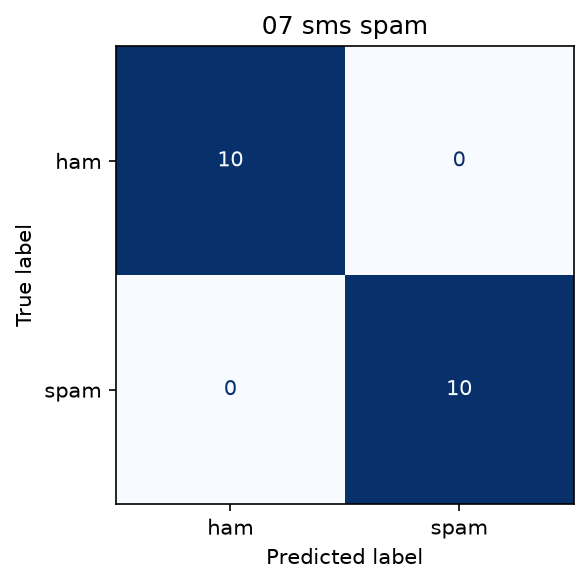

In [3]:
df = pd.read_csv(DATA / 'sms.csv')
X, y = df.text.map(clean_text), df.label
assert not X.duplicated().any()
print('Messages:', len(df), '| Classes:', y.value_counts().to_dict())
model = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), MultinomialNB())
metrics = evaluate(model, X, y, '07_sms_spam')
examples = ['Claim your free cash prize now', 'Meet me at the library tomorrow']
print('New SMS predictions:', model.predict([clean_text(s) for s in examples]))

### Result and conclusion
Measured results: accuracy = 1.0000; macro_f1 = 1.0000; baseline_accuracy = 0.5000. The small authored corpus illustrates the pipeline only. Its test metrics are not a real-world spam benchmark.